# 03. Сравнение моделей

**Вопрос:** какая модель лучше определяет вид пингвина по длине и глубине клюва и насколько мы в этом уверены?

Вся логика живёт в модуле `src/palmer_penguins/models.py` (и покрыта тестами), блокнот только вызывает её и показывает результаты.

**Почему нужна вложенная кросс-валидация.** Если одна и та же кросс-валидация и выбирает гиперпараметры, и оценивает качество, оценка завышена, так как среди $m$ шумных оценок $\hat a_1, \dots, \hat a_m$ мы берём максимум, а

$$
\mathbb{E}\Big[\max_i \hat a_i\Big] \;\geq\; \max_i \mathbb{E}\big[\hat a_i\big].
$$

Вложенная кросс-валидация разделяет роли: внутренний цикл **выбирает** гиперпараметры, внешний **оценивает** на данных, не участвовавших в выборе.

In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from palmer_penguins.data import PROJECT_ROOT, load_clean
from palmer_penguins.models import (
    FEATURES,  # ["bill_length_mm", "bill_depth_mm"]
    TARGET,  # "species"
    candidates,  # модели-кандидаты и сетки гиперпараметров
    compare_models,  # честная и наивная оценки всех кандидатов
    fit_final,  # подбор гиперпараметров + обучение на всех данных
    mcnemar_exact,  # тест значимости различия двух моделей
    naive_cv_score,  # завышенная оценка (для сравнения)
    nested_cv_predict,  # предсказания вложенной кросс-валидации
)

FIG = PROJECT_ROOT / "reports" / "figures"

In [ ]:
df = load_clean()
X = df[FEATURES]
y = df[TARGET]
X.shape

(342, 2)

## 1. Честная и наивная оценки

Кандидаты: константная модель (`baseline`), логистическая регрессия, $k$ ближайших соседей, дерево решений, случайный лес, SVM с RBF-ядром. У каждой (кроме константы) гиперпараметры подбираются перебором по сетке.

Столбцы таблицы:
- `nested` — честная точность вложенной кросс-валидации;
- `naive` — лучший результат подбора гиперпараметров (завышенная оценка);
- `optimism` = `naive` − `nested`.

In [ ]:
table, predictions = compare_models(X, y)
table.round(3)

,nested,naive,optimism
model,,,
forest,0.962,0.959,-0.003
knn,0.962,0.965,0.003
svm,0.956,0.968,0.012
logreg,0.953,0.965,0.012
tree,0.944,0.947,0.003
baseline,0.442,0.442,-0.000


Все пять настоящих моделей дают 94–96% против 44% у константы. Разница между лучшей и худшей из них - это около 6 пингвинов из 342, а одна ошибка — это $1/342 \approx 0.3\%$. Такие различия вполне могут быть шумом. Проверим это тестом.

На одном разбиении оптимизм скачет (может быть даже отрицательным) - это тоже шум, поэтому ниже усредним его по нескольким разбиениям.

## 2. Значимы ли различия: тест Макнемара

Обе модели предсказывали **одних и тех же** пингвинов, поэтому информативны только расхождения:
- $b$ — сколько пингвинов лучшая модель угадала, а другая нет;
- $c$ — наоборот.

Если модели одинаково точны ($H_0$), каждое расхождение как подброс честной монеты

$$
b \sim \operatorname{Bin}\!\left(b + c,\ \tfrac12\right).
$$

In [ ]:
best = table.index[
    0
]  # имя модели в первой строке лучшей по честной оценке (в нашем случае это случайный лес)

rows = []
for name in table.index[1:]:  # все остальные модели
    # b, c и p-значение для пары "лучшая против этой"
    b, c, p = mcnemar_exact(y, predictions[best], predictions[name])
    rows.append({"против": name, "b": b, "c": c, "p-значение": p})

pd.DataFrame(rows).set_index("против").round(4)

,b,c,p-значение
против,,,
knn,5,5,1.0000
svm,7,5,0.7744
logreg,7,4,0.5488
tree,6,0,0.0312
baseline,182,4,0.0000


Сравнений пять, поэтому нужна поправка на множественность. Поправка Холма сортирует p-значения по возрастанию и сравнивает $k$-е с $\alpha / (m - k + 1)$, пока сравнение проходит:

- самое маленькое $p$ (против константы) $\ll 0.05/5$ — модель значимо лучше константы;
- следующее ($\approx 0.031$, против дерева) $> 0.05/4 = 0.0125$ — здесь останавливаемся.

**Вывод:** после поправки значимо только превосходство над константой. Различия между настоящими моделями статистически не подтверждаются.

## 3. Оптимизм наивной оценки в среднем

Неравенство из начала блокнота — про среднее. Повторим всё на 5 разных разбиениях и усредним оптимизм. Это самая долгая ячейка (около минуты).

In [ ]:
optimism = {name: [] for name in candidates()}

for seed in range(5):
    for name, (pipeline, grid) in candidates().items():
        pred = nested_cv_predict(pipeline, grid, X, y, seed)
        nested = np.mean(pred == y)
        naive = naive_cv_score(pipeline, grid, X, y, seed)
        optimism[name].append(naive - nested)

summary = pd.DataFrame(
    {
        "средний оптимизм": {n: np.mean(v) for n, v in optimism.items()},
        "разброс": {n: np.std(v) for n, v in optimism.items()},
    }
)
summary.round(4)

,средний оптимизм,разброс
baseline,-0.0000,0.0000
logreg,0.0018,0.0039
knn,0.0047,0.0057
tree,0.0059,0.0132
forest,0.0053,0.0089
svm,0.0094,0.0028


Теория подтверждается:
- у всех моделей с гиперпараметрами средний оптимизм положителен - наивная оценка в среднем завышена;
- у константы он ровно ноль. так как ей нечего выбирать, а без выбора максимума нет и смещения (при $m = 1$ неравенство превращается в равенство);
- сильнее всего завышена оценка SVM - у него самая большая сетка (12 вариантов), поэтому чем больше выбор, тем больше "везения" попадает в максимум.

## 4. Границы решений

Признаков два, поэтому любая модель - это функция $f: \mathbb{R}^2 \to \{\text{Adelie}, \text{Chinstrap}, \text{Gentoo}\}$, и её можно нарисовать, то есть раскрасить каждую точку плоскости цветом предсказанного вида.

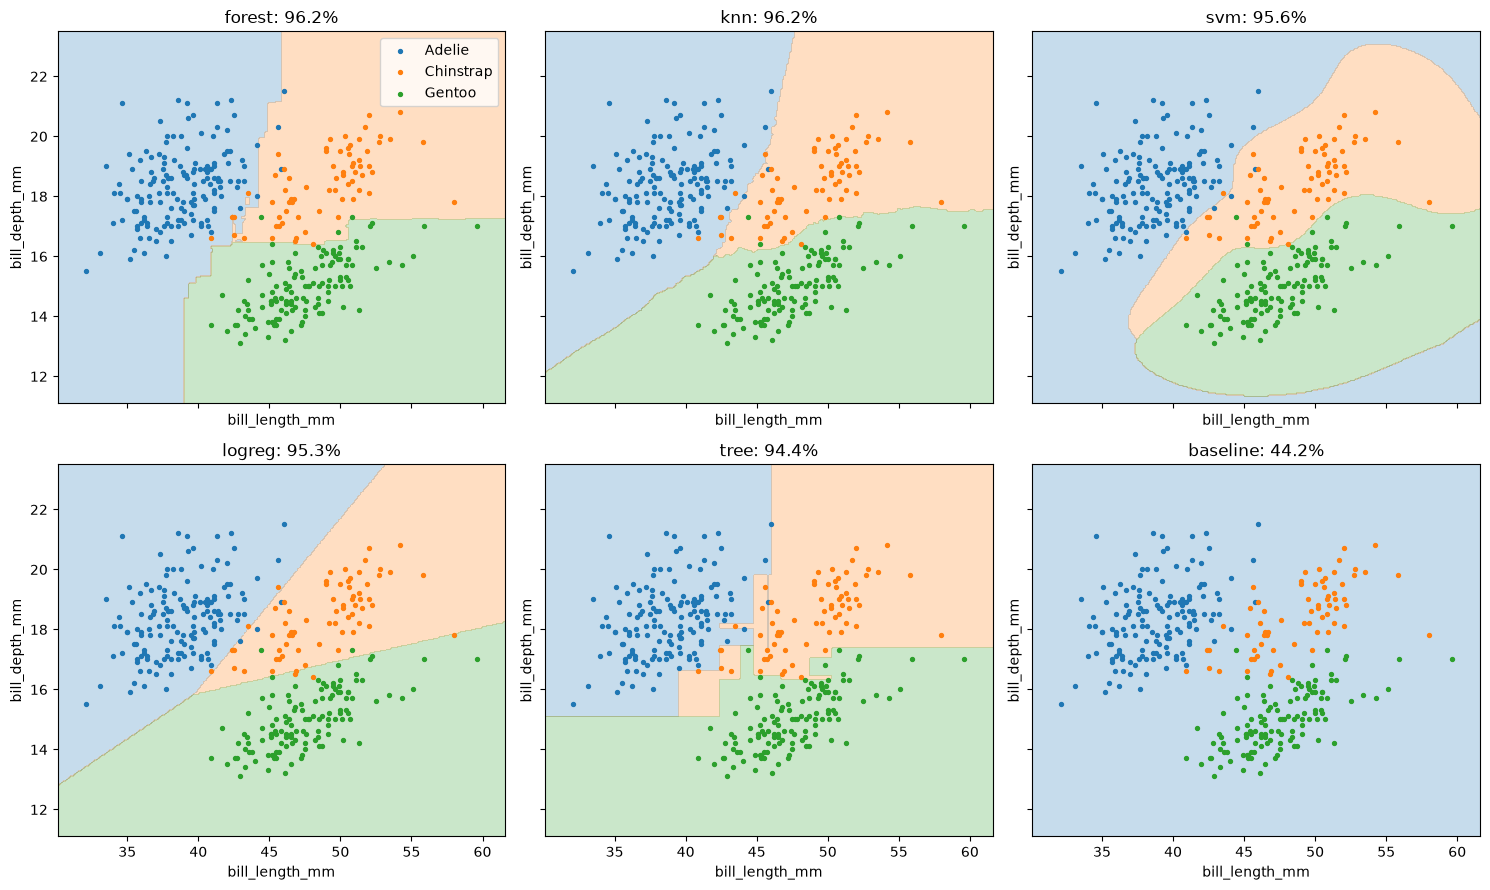

In [ ]:
SPECIES = sorted(y.unique())
COLORS = sns.color_palette()[: len(SPECIES)]


def plot_decision_boundary(model, X, y, ax, title):
    """Раскрасить плоскость по предсказаниям модели и нанести точки данных."""
    x_col, y_col = X.columns

    # 300 равноотстоящих значений по каждой оси, с запасом 2 мм за краями данных.
    xs = np.linspace(X[x_col].min() - 2, X[x_col].max() + 2, 300)
    ys = np.linspace(X[y_col].min() - 2, X[y_col].max() + 2, 300)

    # Сетка = декартово произведение xs × ys: две матрицы 300 × 300,
    # xx[i, j] и yy[i, j] — координаты точки (i, j). Всего 90 000 точек.
    xx, yy = np.meshgrid(xs, ys)

    # ravel() вытягивает матрицу в вектор; имена столбцов — как в X,
    # потому что модель ожидает именно их.
    grid = pd.DataFrame({x_col: xx.ravel(), y_col: yy.ravel()})
    predicted = model.predict(grid)  # вид для каждой из 90 000 точек

    # Названия видов это числа 0, 1, 2, затем вектор обратно в матрицу 300 × 300.
    codes = pd.Categorical(predicted, categories=SPECIES).codes.reshape(xx.shape)

    # Заливка областей: уровни -0.5, 0.5, 1.5, 2.5 разделяют значения 0, 1, 2,
    # так что каждый вид получает свой цвет. alpha — полупрозрачность.
    ax.contourf(xx, yy, codes, levels=[-0.5, 0.5, 1.5, 2.5], colors=COLORS, alpha=0.25)

    # Поверх заливки — настоящие пингвины, каждый вид своим цветом.
    # strict=True если длины списков разойдутся, будет ошибка,
    # а не молчаливое обрезание более длинного списка.
    for species, color in zip(SPECIES, COLORS, strict=True):
        mask = y == species  # True у пингвинов этого вида
        ax.scatter(
            X.loc[mask, x_col], X.loc[mask, y_col], s=8, color=color, label=species
        )

    ax.set_title(title)
    ax.set_xlabel(x_col)
    ax.set_ylabel(y_col)


fig, axes = plt.subplots(2, 3, figsize=(15, 9), sharex=True, sharey=True)

for ax, name in zip(axes.ravel(), table.index, strict=True):
    model, params = fit_final(name, X, y)
    title = f"{name}: {table.loc[name, 'nested']:.1%}"
    plot_decision_boundary(model, X, y, ax, title)

axes[0, 0].legend()
fig.tight_layout()
fig.savefig(FIG / "decision_boundaries.png", dpi=100)

Формы границ отражают устройство моделей:
- logreg - прямые (линейная модель);
- svm - плавные кривые (RBF-ядро);
- knn - рваные, повторяют расположение соседних точек;
- tree - ступеньки;
- forest - ступеньки сложнее;
- baseline - вся плоскость одного цвета.

Принципиально разные границы дают почти одинаковую точность, потому что три облака разделяет почти любая разумная граница, спорные только пингвины в зонах перекрытия.

## 5. Итоговая модель

Различия между моделями незначимы, поэтому выбираем самую простую, то есть логистическую регрессию. У неё линейные понятные границы, мало параметров и осмысленные вероятности классов.

Итоговая модель получается применением той же процедуры ко всем данным. Честная оценка её качества - точность `nested` из таблицы выше (95.3%), а не `best_score_` этого подбора.

In [7]:
# final_model — обученный пайплайн (стандартизация + регрессия), готовый предсказывать;
# final_params — выбранные гиперпараметры.
final_model, final_params = fit_final("logreg", X, y)
final_params

{'model__C': 100}